# LeNet transfer learning
LeNet was trained on MNIST. Real handwriting looks different, so here I fine-tune it on the Swiss digits dataset
(Kaggle, olafkrastovski, CC0) and compare before and after.

In [2]:
import sys
sys.path.insert(0, "..")

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from hnrs.preprocessing import load_swiss_digits, load_preprocessed_mnist
from hnrs.models.lenet import build_model, fine_tune_model, MODEL_PATH, MIXED_PATH
from hnrs.preprocess_image import preprocess_image

# Swiss digits: 80/20 split, already preprocessed into MNIST format
x_train, y_train, x_test, y_test = load_swiss_digits()
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# MNIST, to check fine-tuning doesn't make it forget MNIST,
# and to mix into the training data in section 2b
mnist_x_train, mnist_y_train, _, mnist_x_test, mnist_y_test, _ = load_preprocessed_mnist()
mnist_x_train = np.expand_dims(mnist_x_train, axis=-1)
mnist_x_test = np.expand_dims(mnist_x_test, axis=-1)

print(x_train.shape, x_test.shape, mnist_x_test.shape)

(17247, 28, 28, 1) (4308, 28, 28, 1) (10000, 28, 28, 1)


## 1. Original LeNet on Swiss digits

In [3]:
original = tf.keras.models.load_model(MODEL_PATH)

_, swiss_acc = original.evaluate(x_test, y_test, verbose=0)
_, mnist_acc = original.evaluate(mnist_x_test, mnist_y_test, verbose=0)
print(f"Original LeNet  Swiss: {swiss_acc:.4f}  MNIST: {mnist_acc:.4f}")

original_pred = original.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, original_pred, digits=4))

Original LeNet  Swiss: 0.9081  MNIST: 0.9897
              precision    recall  f1-score   support

           0     0.9761    0.9150    0.9446       447
           1     0.9125    0.8616    0.8863       448
           2     0.9100    0.9753    0.9416       446
           3     0.8708    0.9341    0.9013       440
           4     0.9102    0.8621    0.8855       435
           5     0.9303    0.9741    0.9517       425
           6     0.8665    0.9646    0.9129       424
           7     0.8827    0.9433    0.9120       423
           8     0.8811    0.9065    0.8936       417
           9     0.9673    0.7345    0.8350       403

    accuracy                         0.9081      4308
   macro avg     0.9108    0.9071    0.9065      4308
weighted avg     0.9108    0.9081    0.9070      4308



## 2. Fine-tune: freeze the conv layers, retrain the dense layers

In [4]:
finetuned, history = fine_tune_model(x_train, y_train, epochs=5)

_, swiss_acc = finetuned.evaluate(x_test, y_test, verbose=0)
_, mnist_acc = finetuned.evaluate(mnist_x_test, mnist_y_test, verbose=0)
print(f"Fine-tuned LeNet  Swiss: {swiss_acc:.4f}  MNIST: {mnist_acc:.4f}")

finetuned_pred = finetuned.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, finetuned_pred, digits=4))

Epoch 1/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9604 - loss: 0.1382 - val_accuracy: 0.9623 - val_loss: 0.1155
Epoch 2/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9786 - loss: 0.0758 - val_accuracy: 0.9699 - val_loss: 0.1021
Epoch 3/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9859 - loss: 0.0514 - val_accuracy: 0.9716 - val_loss: 0.1011
Epoch 4/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9905 - loss: 0.0357 - val_accuracy: 0.9757 - val_loss: 0.0987
Epoch 5/5
486/486 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9939 - loss: 0.0250 - val_accuracy: 0.9768 - val_loss: 0.1021
Fine-tuned LeNet  Swiss: 0.9756  MNIST: 0.9321
              precision    recall  f1-score   support

           0     0.9774    0.9687    0.9730       447
           1     0.9824    0.9955    0.9889       448
           2     0.9866    0.9933    0.9899       446
           3     0.9658    0.9636    0.9647       440
           4     0.9794    0.9839    0.9817    

## 2b. Fine-tune on a mix of MNIST and Swiss
Fine-tuning on Swiss alone made the model misread my 7s (no crossbar) as 1s, because Swiss 1s have a long flag.
Mixing in the same amount of MNIST should let it learn both styles.

In [5]:
# Same number of MNIST and Swiss images, so neither style dominates
rng = np.random.default_rng(42)
pick = rng.choice(len(mnist_x_train), size=len(x_train), replace=False)

mixed_x = np.concatenate([x_train, mnist_x_train[pick]])
mixed_y = np.concatenate([y_train, mnist_y_train[pick]])

order = rng.permutation(len(mixed_x))  # shuffle so batches contain both styles
mixed_x, mixed_y = mixed_x[order], mixed_y[order]

mixed, mixed_history = fine_tune_model(mixed_x, mixed_y, epochs=5, save_path=MIXED_PATH)

_, swiss_acc = mixed.evaluate(x_test, y_test, verbose=0)
_, mnist_acc = mixed.evaluate(mnist_x_test, mnist_y_test, verbose=0)
print(f"Mixed fine-tuned LeNet  Swiss: {swiss_acc:.4f}  MNIST: {mnist_acc:.4f}")

Epoch 1/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9744 - loss: 0.0892 - val_accuracy: 0.9800 - val_loss: 0.0644
Epoch 2/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9841 - loss: 0.0562 - val_accuracy: 0.9786 - val_loss: 0.0643
Epoch 3/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9882 - loss: 0.0411 - val_accuracy: 0.9803 - val_loss: 0.0674
Epoch 4/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9914 - loss: 0.0309 - val_accuracy: 0.9786 - val_loss: 0.0740
Epoch 5/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9933 - loss: 0.0250 - val_accuracy: 0.9777 - val_loss: 0.0735
Mixed fine-tuned LeNet  Swiss: 0.9721  MNIST: 0.9852


## 3. Accuracy per digit, before vs after

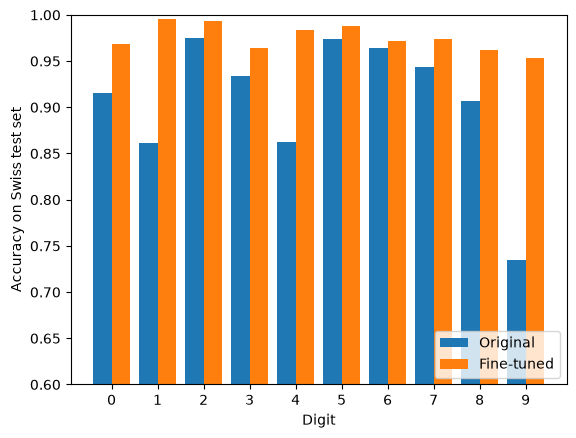

In [6]:
before = [(original_pred[y_test == d] == d).mean() for d in range(10)]
after = [(finetuned_pred[y_test == d] == d).mean() for d in range(10)]

x = np.arange(10)
plt.bar(x - 0.2, before, width=0.4, label="Original")
plt.bar(x + 0.2, after, width=0.4, label="Fine-tuned")
plt.xticks(x)
plt.ylim(0.6, 1.0)
plt.xlabel("Digit")
plt.ylabel("Accuracy on Swiss test set")
plt.legend(loc="lower right")
plt.savefig("../docs/images/lenet_transfer_per_digit.png", dpi=150)
plt.show()

## 4. Does transfer learning help more when there's less data?
Train on only n Swiss images, either from scratch or starting from the MNIST LeNet.

In [7]:
def from_scratch(n):
    model = build_model()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(x_train[:n], y_train[:n], epochs=5, verbose=0)
    return model.evaluate(x_test, y_test, verbose=0)[1]

def with_transfer(n):
    model, _ = fine_tune_model(x_train[:n], y_train[:n], epochs=5, save_path=None)
    return model.evaluate(x_test, y_test, verbose=0)[1]

print("train size | from scratch | transfer")
for n in [200, 1000, len(x_train)]:
    print(f"{n:10d} | {from_scratch(n):.4f}       | {with_transfer(n):.4f}")

train size | from scratch | transfer
Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9222 - loss: 0.2452 - val_accuracy: 1.0000 - val_loss: 0.0271
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9778 - loss: 0.1165 - val_accuracy: 1.0000 - val_loss: 0.0292
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9944 - loss: 0.0712 - val_accuracy: 1.0000 - val_loss: 0.0364
Epoch 4/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9944 - loss: 0.0484 - val_accuracy: 1.0000 - val_loss: 0.0403
Epoch 5/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9944 - loss: 0.0332 - val_accuracy: 1.0000 - val_loss: 0.0415
       200 | 0.6834       | 0.9320
Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9200 - loss: 0.2577 - val_accuracy: 0.9400 - val_loss: 0.1869
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9711 - loss: 0.0984 - val_accuracy: 0.9500 - val_loss: 0.1774
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0

## 5. My own handwriting
The fully independent test: photos I wrote and took myself, never used for training.

In [8]:
import os, glob

# My own handwriting photos, named by label: 0_1.jpg, 0_2.jpg, 1_1.jpg ...
paths = sorted(glob.glob("../data/handwritten/*"))
paths = [p for p in paths if p.lower().endswith((".jpg", ".jpeg", ".png"))]

names, labels, digits = [], [], []
for path in paths:
    name = os.path.basename(path)
    if not name[0].isdigit():
        print(f"{name}: not named by label, skipped")
        continue
    try:
        digits.append(preprocess_image(path))
    except ValueError:
        print(f"{name}: no digit found, skipped")
        continue
    names.append(name)
    labels.append(int(name[0]))

photos = np.expand_dims(np.array(digits), axis=-1)
labels = np.array(labels)

original_photo_pred = original.predict(photos, verbose=0).argmax(axis=1)
finetuned_photo_pred = finetuned.predict(photos, verbose=0).argmax(axis=1)
mixed_photo_pred = mixed.predict(photos, verbose=0).argmax(axis=1)

print(f"{len(labels)} photos")
print(f"Original LeNet:   {(original_photo_pred == labels).mean():.1%}")
print(f"Fine-tuned LeNet: {(finetuned_photo_pred == labels).mean():.1%}")
print(f"Mixed LeNet:      {(mixed_photo_pred == labels).mean():.1%}")

# Which photos did each model get wrong?
for name, true, a, b, c in zip(names, labels, original_photo_pred, finetuned_photo_pred, mixed_photo_pred):
    if a != true or b != true or c != true:
        print(f"  {name}: true {true}, original {a}, fine-tuned {b}, mixed {c}")

29 photos
Original LeNet:   93.1%
Fine-tuned LeNet: 82.8%
Mixed LeNet:      86.2%
  1_0.jpg: true 1, original 1, fine-tuned 2, mixed 2
  3_0.jpg: true 3, original 2, fine-tuned 2, mixed 2
  7_0.jpg: true 7, original 7, fine-tuned 1, mixed 1
  7_2.jpg: true 7, original 4, fine-tuned 6, mixed 6
  7_3.jpg: true 7, original 7, fine-tuned 9, mixed 7


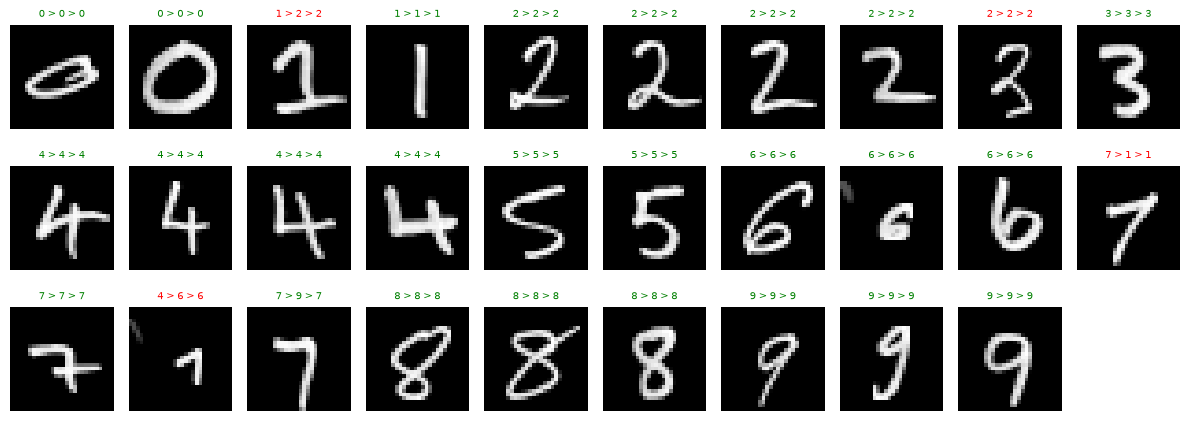

In [9]:
# Grid: preprocessed photo, with original > fine-tuned > mixed prediction
# Green = mixed model correct, red = mixed model wrong
cols = 10
rows = int(np.ceil(len(labels) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.5))
for ax in np.array(axes).flat:
    ax.axis("off")
for ax, digit, true, a, b, c in zip(np.array(axes).flat, digits, labels, original_photo_pred, finetuned_photo_pred, mixed_photo_pred):
    ax.imshow(digit, cmap="gray")
    ax.set_title(f"{a} > {b} > {c}", color="green" if c == true else "red", fontsize=7)
plt.tight_layout()
plt.savefig("../docs/images/handwritten_transfer.png", dpi=150)
plt.show()

## 6. Summary

In [10]:
models = {"Original": original, "Fine-tuned (Swiss)": finetuned, "Fine-tuned (mixed)": mixed}

print(f"{'':22s} {'Swiss':>8s} {'MNIST':>8s} {'My photos':>10s}")
for name, model in models.items():
    swiss = model.evaluate(x_test, y_test, verbose=0)[1]
    mnist = model.evaluate(mnist_x_test, mnist_y_test, verbose=0)[1]
    mine = (model.predict(photos, verbose=0).argmax(axis=1) == labels).mean()
    print(f"{name:22s} {swiss:8.1%} {mnist:8.1%} {mine:10.1%}")

                          Swiss    MNIST  My photos
Original                  90.8%    99.0%      93.1%
Fine-tuned (Swiss)        97.6%    93.2%      82.8%
Fine-tuned (mixed)        97.2%    98.5%      86.2%
